In [1]:
## WORK IN PROGRESS

In [2]:
%pip install seaborn matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: C:\Users\tngya\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import PercentFormatter

In [4]:
df = pd.read_csv("../dataset/hotel_booking_cleaned.csv")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 41 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   booking_id                      119390 non-null  int64  
 1   hotel                           119390 non-null  str    
 2   is_canceled                     119390 non-null  int64  
 3   lead_time                       119390 non-null  int64  
 4   arrival_date_year               119390 non-null  int64  
 5   arrival_date_month              119390 non-null  str    
 6   arrival_date_week_number        119390 non-null  int64  
 7   arrival_date_day_of_month       119390 non-null  int64  
 8   stays_in_weekend_nights         119390 non-null  int64  
 9   stays_in_week_nights            119390 non-null  int64  
 10  adults                          119390 non-null  int64  
 11  children                        119390 non-null  float64
 12  babies                     

In [5]:
## Overall booking summary

In [6]:
# Total number of bookings
total_bookings = len(df)
total_bookings_by_hotel = df.groupby('hotel').size()

canceled_by_hotel = df[df['reservation_status'] == 'Canceled'].groupby('hotel').size()
cancellation_rate = canceled_by_hotel / total_bookings_by_hotel 

rev_by_hotel = df.groupby('hotel')['estimated_room_revenue'].sum()
nights_by_hotel = df.groupby('hotel')['total_nights'].sum()
weighted_adr_by_hotel = rev_by_hotel / nights_by_hotel
overall_adr = df['estimated_room_revenue'].sum() / df['total_nights'].sum()


hotel_summary = pd.DataFrame({
    'Total Bookings': total_bookings_by_hotel,
    'Canceled Bookings': canceled_by_hotel,
    'Canceled Rate': cancellation_rate,
    'Weighted ADR': weighted_adr_by_hotel
})

total_canceled = (df['reservation_status'] == 'Canceled').sum()
overall_canceled_rate = total_canceled / total_bookings

hotel_summary.loc['Overall'] = [
    total_bookings,
    total_canceled,
    overall_canceled_rate,
    overall_adr
]


hotel_summary

,Total Bookings,Canceled Bookings,Canceled Rate,Weighted ADR
hotel,,,,
City Hotel,79330.0,32186.0,0.405723,60.927173
Resort Hotel,40060.0,10831.0,0.270369,67.062699
Overall,119390.0,43017.0,0.360307,63.520781


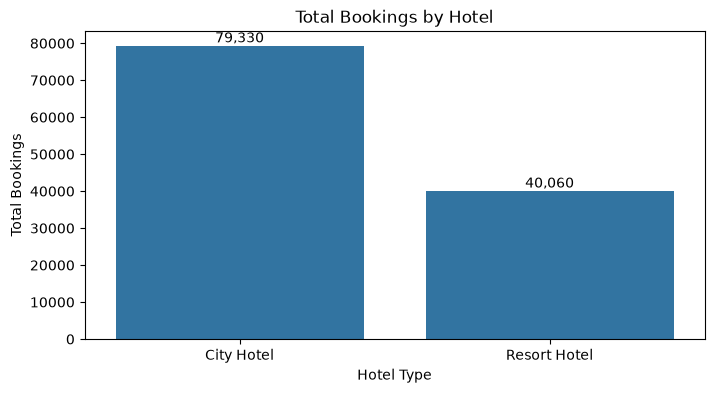

In [7]:
# Total booking bar chart
hotel_plot = hotel_summary.drop('Overall').reset_index()

plt.figure(figsize=(8,4))

ax = sns.barplot(data=hotel_plot,x='hotel',y='Total Bookings')
ax.bar_label(ax.containers[0],fmt='{:,.0f}')

plt.title('Total Bookings by Hotel')
plt.xlabel('Hotel Type')
plt.ylabel('Total Bookings')
plt.show()

In [8]:
# City Hotel accounts for approximately 66.4% of total bookings, receiving nearly twice as many bookings as Resort Hotel. 
# This indicates higher booking volume for City Hotel, although booking volume alone does not reflect actual completed stays or profitability.

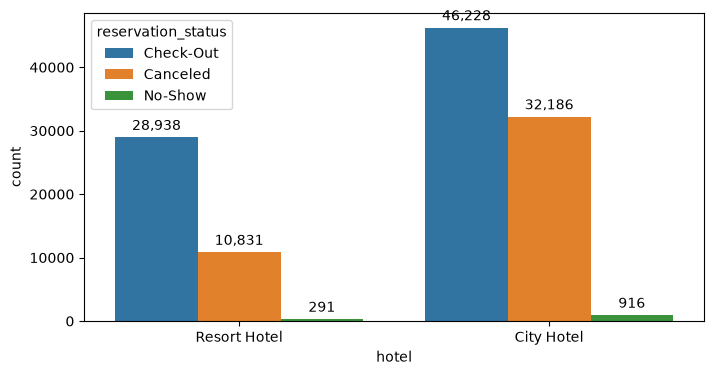

In [9]:
# Booking status by hotel chart
plt.figure(figsize=(8,4))
ax = sns.countplot(data=df,x='hotel',hue='reservation_status')

for container in ax.containers:
    ax.bar_label(container,fmt='{:,.0f}',padding=3)

plt.show()

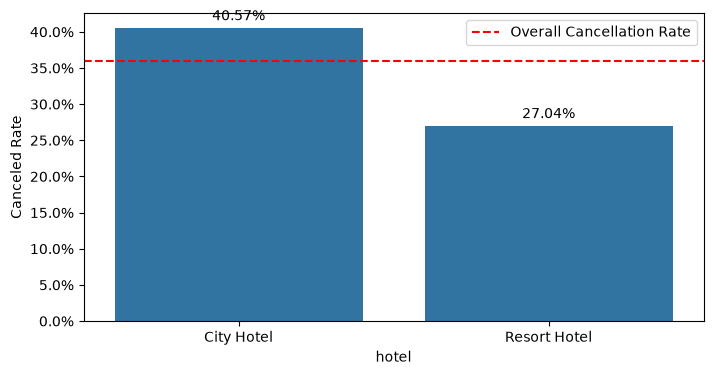

In [10]:
# Cancellation rate chart
plt.figure(figsize=(8,4))
ax = sns.barplot(data=hotel_plot,x='hotel',y='Canceled Rate')

ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.bar_label(ax.containers[0],fmt='{:.2%}',padding=3)

plt.axhline(y=overall_canceled_rate,
            color='red',
            linestyle='--',
            label='Overall Cancellation Rate')
plt.legend()

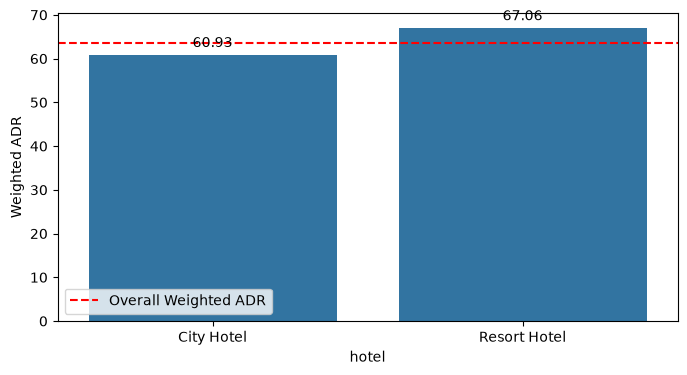

In [11]:
# Weighted ADR by hotel
plt.figure(figsize=(8,4))
ax = sns.barplot(data=hotel_plot,x='hotel',y='Weighted ADR')

ax.bar_label(ax.containers[0],fmt='{:.2f}',padding=3)

plt.axhline(y=overall_adr,
            color='red',
            linestyle='--',
            label='Overall Weighted ADR')
plt.legend()

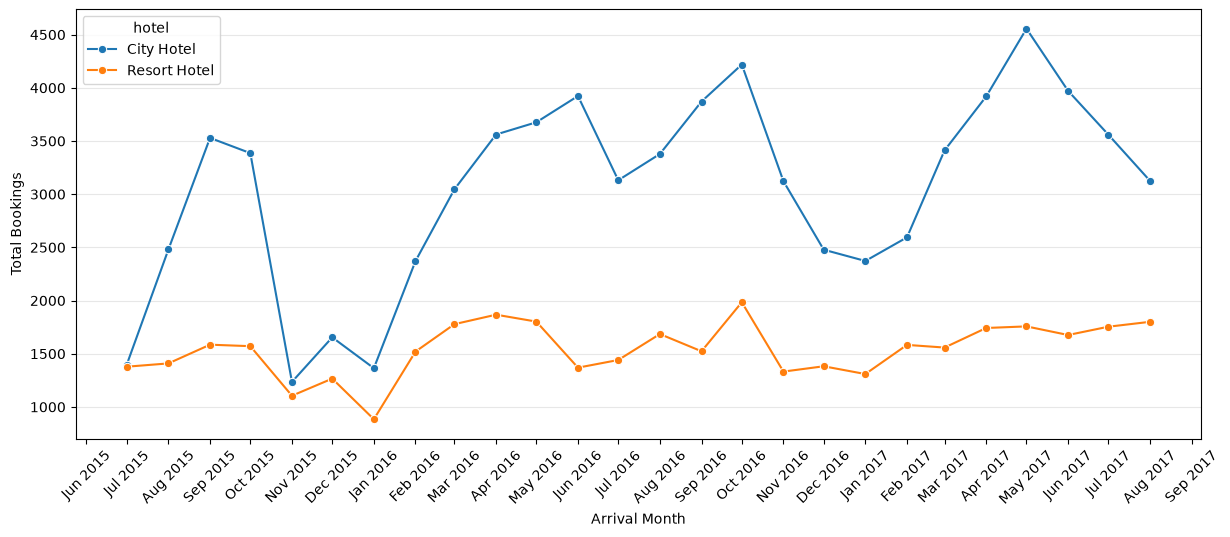

In [44]:
# Monthly trend
df['arrival_date'] = df['arrival_date_year'].astype(str) + '-' + df['arrival_date_month'] + '-' + df['arrival_date_day_of_month'].astype(str)
df['arrival_date'] = pd.to_datetime(df['arrival_date'],format='%Y-%B-%d')

df['arrival_month'] = df['arrival_date'].dt.to_period('M')
monthly_bookings = df.groupby(
    ['arrival_month','hotel']).size().reset_index(name='Total Bookings')
monthly_bookings['arrival_month'] = monthly_bookings['arrival_month'].dt.to_timestamp()

plt.figure(figsize=(12,5))
plt.xticks(rotation=45)
plt.tight_layout()
plt.grid(axis='y',alpha=0.3)
plt.xlabel('Arrival Month')

ax = sns.lineplot(
    data=monthly_bookings,
    x='arrival_month',
    y='Total Bookings',
    hue='hotel',
    marker='o')

ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=1))

<Axes: xlabel='Month Number', ylabel='Average Monthly Bookings'>

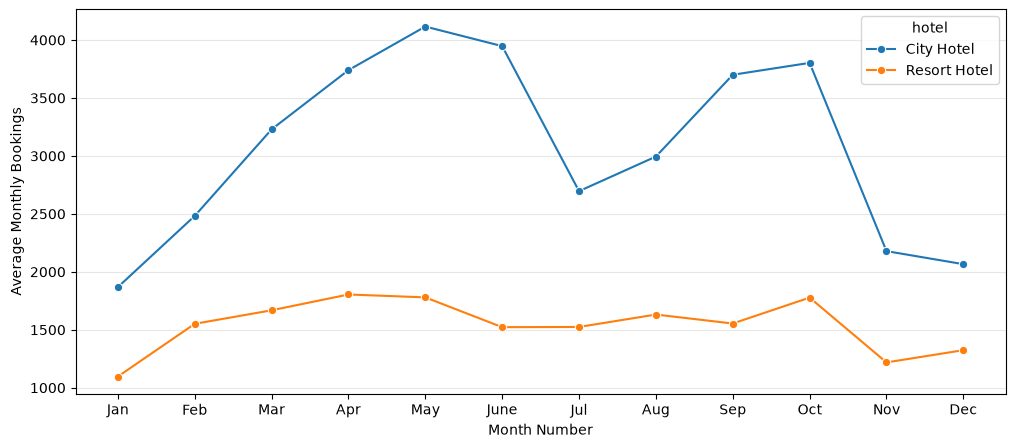

In [41]:
# Seasonal Average Monthly Booking
monthly_bookings['month_number'] = monthly_bookings['arrival_month'].dt.month
seasonal_bookings = monthly_bookings.groupby(['hotel','month_number'])['Total Bookings'].mean().reset_index(
    name='Average Monthly Bookings')

plt.figure(figsize=(12,5))
plt.xlabel('Month Number')
plt.xticks(
    ticks=range(1,13),
    labels=['Jan','Feb','Mar','Apr','May','June',
            'Jul','Aug','Sep','Oct','Nov','Dec']
)
plt.grid(axis='y',alpha=0.3)

sns.lineplot(
    data=seasonal_bookings,
    x='month_number',
    y='Average Monthly Bookings',
    hue='hotel',
    marker='o')

<Axes: xlabel='Month Number', ylabel='Cancellation Rate'>

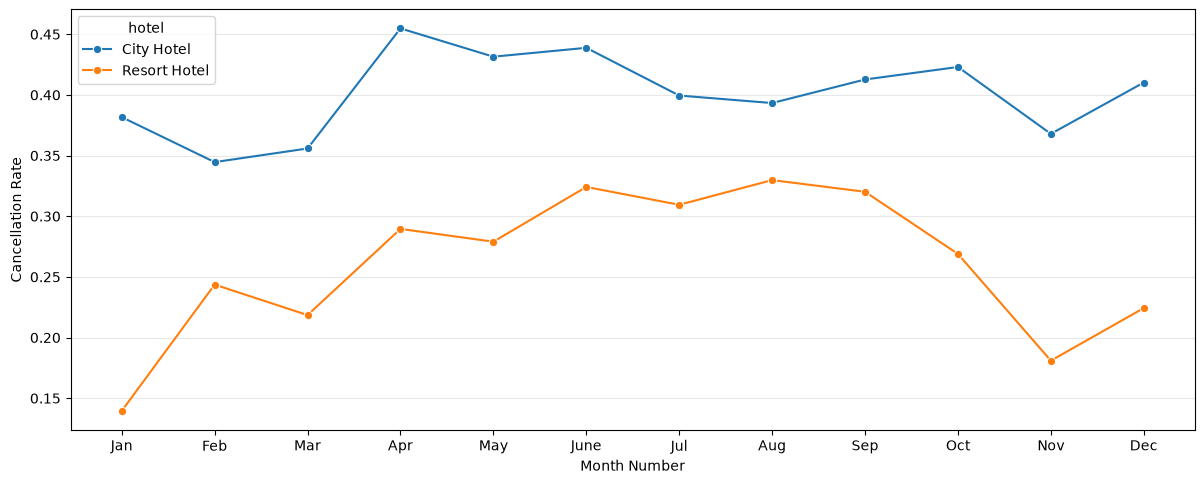

In [45]:
# Seasonal Cancellation Rate
df['month_number'] = df['arrival_date'].dt.month
canceled = df[
    df['reservation_status'] == 'Canceled'].groupby(['hotel','month_number']).size()

total_monthly_bookings = df.groupby(['hotel','month_number']).size()

seasonal_cancellation_rate = canceled/total_monthly_bookings
seasonal_cancellation = seasonal_cancellation_rate.reset_index(name='Cancellation Rate')

plt.figure(figsize=(12,5))
plt.grid(axis='y',alpha=0.3)
plt.xticks(
    ticks=range(1,13),
    labels=['Jan','Feb','Mar','Apr','May','June',
            'Jul','Aug','Sep','Oct','Nov','Dec']
)
plt.xlabel('Month Number')
plt.tight_layout()

sns.lineplot(
    data=seasonal_cancellation,
    x='month_number',
    y='Cancellation Rate',
    hue='hotel',
    marker='o'
)

In [ ]:
# Seasonal Weighted ADR


In [28]:
monthly_bookings.head()

,arrival_month,hotel,Total Bookings,month_number
0,2015-07-01,City Hotel,1398,7
1,2015-07-01,Resort Hotel,1378,7
2,2015-08-01,City Hotel,2480,8
3,2015-08-01,Resort Hotel,1409,8
4,2015-09-01,City Hotel,3529,9


In [ ]:
# Cancellation seasonality analysis
Total cancelation --> 'reservation status' = 'Canceled'


plt.figure(figsize=(12,5))

sns.lineplot(
    data=monthly_bookings,
    x='hotel',
    y='Canceled Bookings',
    hue='hotel'

In [19]:
# No-show analysis
no_show_by_hotel = df[df['reservation_status'] == 'No-Show'].groupby('hotel').size()
no_show_rate = no_show_by_hotel / total_bookings_by_hotel

no_show_summary = pd.DataFrame({
    'Total No-Show Bookings': no_show_by_hotel,
    'No-Show Rate': no_show_rate
})

total_no_show = (df['reservation_status'] == 'No-Show').sum()
overall_rate = total_no_show / total_bookings

no_show_summary.loc['Overall'] = [
    total_no_show,
    overall_rate
]

no_show_summary

,Total No-Show Bookings,No-Show Rate
hotel,,
City Hotel,916.0,0.011547
Resort Hotel,291.0,0.007264
Overall,1207.0,0.010110


In [16]:
# Completed booking analysis
completed_by_hotel = df[df['reservation_status'] == 'Check-Out'].groupby('hotel').size()
completion_rate = completed_by_hotel / total_bookings_by_hotel

completion_summary = pd.DataFrame({
    'Total Completed Bookings': completed_by_hotel,
    'Completion Rate': completion_rate
})

total_completed_bookings = (df['reservation_status'] == 'Check-Out').sum()
overall_rate = total_completed_bookings / total_bookings

completion_summary.loc['Overall'] = [
    total_completed_bookings,
    overall_rate
]

completion_summary

,Total Completed Bookings,Completion Rate
hotel,,
City Hotel,46228.0,0.582730
Resort Hotel,28938.0,0.722366
Overall,75166.0,0.629584


In [17]:
## Hotel performance analysis

In [18]:
# Cancel